# 📊 Étape 3 : Analyse bivariée (R Notebook)
**Dataset :** Diabetes Health Indicators, BRFSS 2015 (Kaggle), 253 680 personnes

**Réalisé par :** Mohammed Nezhari, Soufiane Ait ouchn et Abdelouafi Er-raqui
**Encadré par :** Pr. Zineb BOUSBAA

---
L'analyse bivariée étudie la **relation entre deux variables numériques** X et Y. Nous suivons les étapes du cours (chapitre 2) :
1. **Nuage de points** : quel type de relation ? Linéaire, non linéaire, ou aucune relation.
2. **Linéariser** la relation si besoin, par **transformation** ou par **restriction**, puis comparer avec le **R² ajusté** et le **coefficient de Pearson**.
3. **Force de la liaison** : coefficient de Pearson r et **test d'hypothèse** H0 : ρ = 0 (`cor.test`).
4. **Décision :**
   - **cas 1** (explicative et cible) : garder la variable ou non ;
   - **cas 2** (deux explicatives) : y a-t-il de la multicolinéarité ?

Nous étudions deux couples de variables :
| Couple | X | Y | Cas du cours |
|---|---|---|---|
| **A** | Income (revenu, de 1 à 8) | PhysHlth (jours malade, de 0 à 30) | **Cas 2** : deux variables explicatives |
| **B** | BMI (indice de masse corporelle) | Diabetes_012 (0 = non, 1 = prédiabète, 2 = diabète) | **Cas 1** : explicative et variable cible |

In [1]:
# Chargement des données
df <- read.csv("diabetes_012_health_indicators_BRFSS2015.csv")
cat("Nombre de personnes :", nrow(df), "\n")

# Taille des graphiques dans le notebook
options(repr.plot.width = 15, repr.plot.height = 5)

# Échantillon de 5000 personnes pour les nuages de points (253 680 points seraient illisibles)
set.seed(42)
ech <- df[sample(nrow(df), 5000), ]

Nombre de personnes : 253680 


---
## 🔹 Partie A : Income (X) et PhysHlth (Y)
- **Income :** tranche de revenu, de 1 (moins de 10 000 $) à 8 (plus de 75 000 $).
- **PhysHlth :** nombre de jours de mauvaise santé physique sur les 30 derniers jours.

**Question :** les personnes qui gagnent moins sont-elles plus souvent malades ?

### A.1 Rappel univarié rapide

In [2]:
x <- df$Income
y <- df$PhysHlth

summary(x)
summary(y)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  1.000   5.000   7.000   6.054   8.000   8.000 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  0.000   0.000   0.000   4.242   3.000  30.000 

### A.2 Nuage de points : type de relation

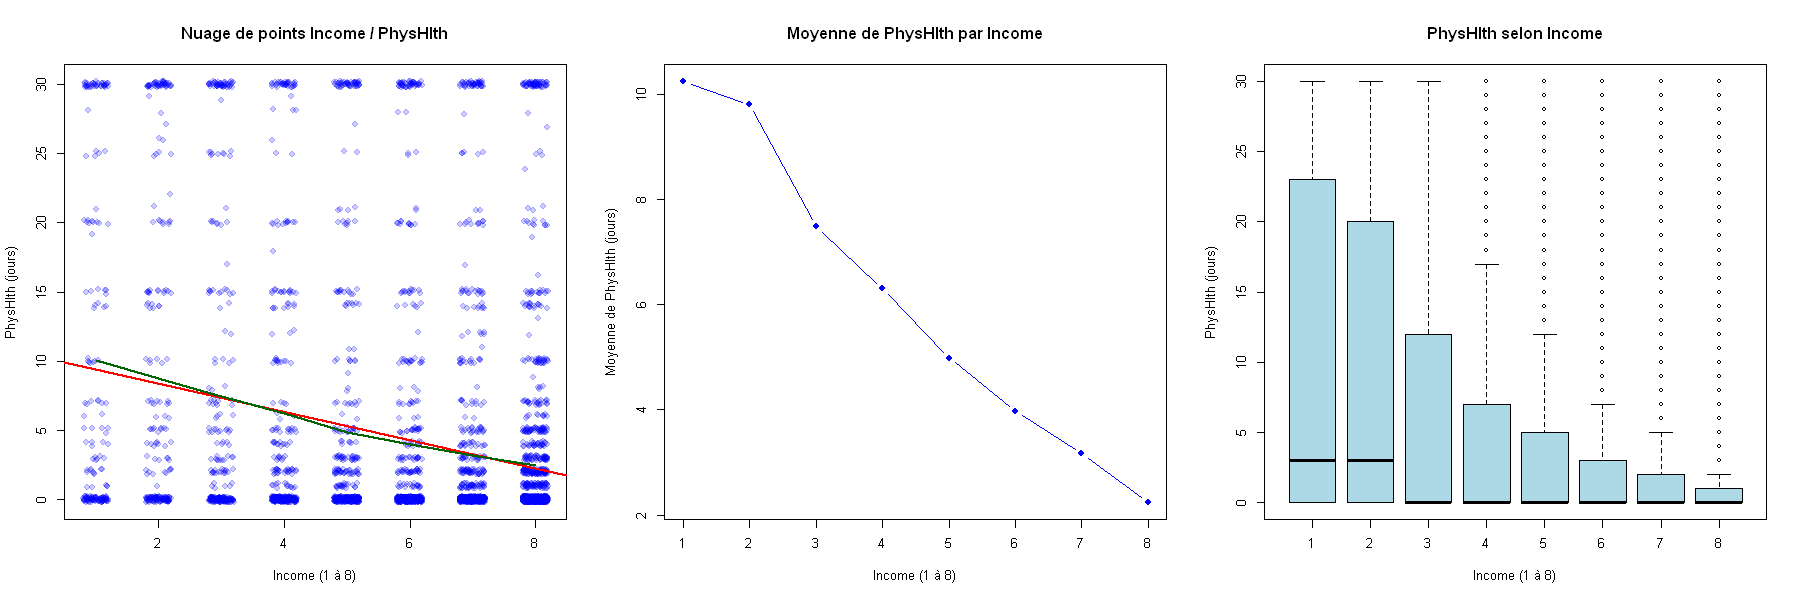

In [3]:
par(mfrow = c(1, 3))

# 1. Nuage de points (jitter pour séparer les points superposés)
plot(jitter(ech$Income), jitter(ech$PhysHlth), main = "Nuage de points Income / PhysHlth",
     col = rgb(0, 0, 1, 0.2), pch = 19, xlab = "Income (1 à 8)", ylab = "PhysHlth (jours)")
abline(lm(PhysHlth ~ Income, data = ech), col = "red", lwd = 2)
lines(lowess(ech$Income, ech$PhysHlth, iter = 0), col = "darkgreen", lwd = 2)  # iter = 0 : suit la moyenne

# 2. Moyenne de PhysHlth pour chaque niveau de revenu
moyennes <- tapply(y, x, mean)
plot(1:8, moyennes, type = "b", pch = 19, col = "blue", main = "Moyenne de PhysHlth par Income",
     xlab = "Income (1 à 8)", ylab = "Moyenne de PhysHlth (jours)")

# 3. Boxplot de PhysHlth selon Income
boxplot(PhysHlth ~ Income, data = df, col = "lightblue", main = "PhysHlth selon Income",
        xlab = "Income (1 à 8)", ylab = "PhysHlth (jours)")

par(mfrow = c(1, 1))

In [4]:
round(moyennes, 2)

1     2     3     4     5     6     7     8 
10.24  9.80  7.48  6.31  4.99  3.97  3.17  2.24

**Interprétation :**
- **Nuage de points :** les points forment des colonnes, car Income n'a que 8 valeurs. Le nuage est **très dispersé**, mais la droite rouge (régression) et la courbe verte (lowess) **descendent** toutes les deux.
- **Moyennes :** la moyenne de PhysHlth baisse **régulièrement** quand le revenu augmente. Elle passe de **10,2 jours** pour Income = 1 à **2,2 jours** pour Income = 8.
- **Type de relation :** une relation **négative**, à peu près **linéaire** (la courbe des moyennes est presque une droite). Plus le revenu est élevé, moins la personne est malade.
- **Boxplot :** la médiane vaut 0 pour presque tous les niveaux, mais les boîtes sont plus hautes pour les petits revenus.

### A.3 Linéariser la relation : transformation et restriction
On compare trois versions avec le **coefficient de Pearson r** et le **R² ajusté** :
1. les **données originales** ;
2. une **transformation logarithmique** : log(1 + PhysHlth). On ajoute 1 parce que log(0) n'existe pas ;
3. une **restriction** : on retire les valeurs aberrantes de PhysHlth (plus de 7,5 jours, selon la règle de l'IQR).

In [5]:
# 1. Données originales
r_orig <- cor(x, y)
r2_orig <- summary(lm(y ~ x))$adj.r.squared

# 2. Transformation logarithmique
y_log <- log(1 + y)
r_log <- cor(x, y_log)
r2_log <- summary(lm(y_log ~ x))$adj.r.squared

# 3. Restriction : on garde PhysHlth <= Q3 + 1.5 * IQR
q1 <- quantile(y, 0.25)
q3 <- quantile(y, 0.75)
borne <- q3 + 1.5 * (q3 - q1)
filtre <- y <= borne
r_res <- cor(x[filtre], y[filtre])
r2_res <- summary(lm(y[filtre] ~ x[filtre]))$adj.r.squared

cat("Borne de restriction :", borne, "jours | personnes gardées :", sum(filtre), "\n\n")
cat("Originales     : r =", round(r_orig, 3), "| R² ajusté =", round(r2_orig, 4), "\n")
cat("Transformation : r =", round(r_log, 3), "| R² ajusté =", round(r2_log, 4), "\n")
cat("Restriction    : r =", round(r_res, 3), "| R² ajusté =", round(r2_res, 4), "\n")

Borne de restriction : 7.5 jours | personnes gardées : 212731 



Originales     : r = -0.267 | R² ajusté = 0.0712 


Transformation : r = -0.264 | R² ajusté = 0.0694 


Restriction    : r = -0.091 | R² ajusté = 0.0082 


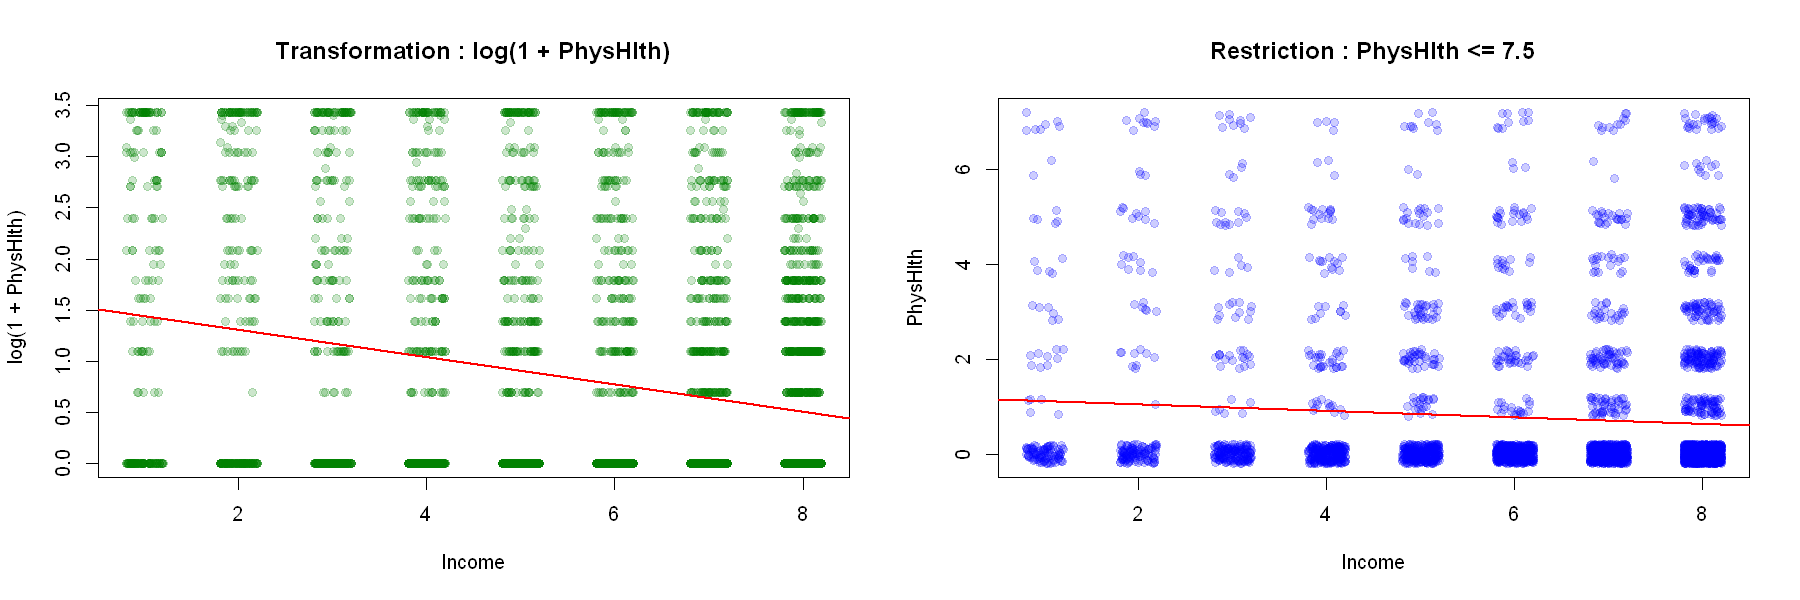

In [6]:
par(mfrow = c(1, 2))

plot(jitter(ech$Income), log(1 + ech$PhysHlth), main = "Transformation : log(1 + PhysHlth)",
     col = rgb(0, 0.5, 0, 0.2), pch = 19, xlab = "Income", ylab = "log(1 + PhysHlth)")
abline(lm(log(1 + PhysHlth) ~ Income, data = ech), col = "red", lwd = 2)

ech_res <- ech[ech$PhysHlth <= borne, ]
plot(jitter(ech_res$Income), jitter(ech_res$PhysHlth), main = "Restriction : PhysHlth <= 7.5",
     col = rgb(0, 0, 1, 0.2), pch = 19, xlab = "Income", ylab = "PhysHlth")
abline(lm(PhysHlth ~ Income, data = ech_res), col = "red", lwd = 2)

par(mfrow = c(1, 1))

**Interprétation :**
| Version | r | R² ajusté |
|---|---|---|
| Données originales | **-0,267** | **0,0712** |
| Transformation log | -0,264 | 0,0694 |
| Restriction (≤ 7,5 jours) | -0,091 | 0,0082 |

- **La transformation n'améliore pas** la relation (r et R² presque identiques). La relation était déjà à peu près linéaire.
- **La restriction détruit la relation** : r passe de -0,27 à -0,09. En retirant les personnes malades plus de 7,5 jours (16 % des données), on retire justement celles qui créent le lien avec le revenu. On **perd de l'information**, comme le cours le signale.
- **Choix :** on garde les **données originales**.

### A.4 Force de la liaison : coefficient de Pearson et test d'hypothèse
**H0 : ρ = 0** (pas de liaison linéaire) contre **H1 : ρ ≠ 0**. Si la p-value est inférieure à 0,05, on rejette H0.

In [7]:
test_A <- cor.test(x, y)

cat("Coefficient de corrélation r :", test_A$estimate, "\n")
cat("p-value du test :", test_A$p.value, "\n")
cat("Spearman (vérification, variable ordinale) :", cor(x, y, method = "spearman"), "\n")

Coefficient de corrélation r : -0.266799 


p-value du test : 0 


Spearman (vérification, variable ordinale) : -0.2180402 


**Interprétation :**
- **r = -0,27** : liaison linéaire **négative** et **faible**. Quand le revenu augmente, le nombre de jours malade diminue un peu.
- **p-value < 0,05** (pratiquement 0) : on **rejette H0**. La liaison existe vraiment, elle n'est pas due au hasard.
- Le coefficient de **Spearman** (-0,22), adapté aux variables ordinales comme Income, confirme le même sens.
- **Pourquoi r est faible alors que le lien est clair ?** Chaque niveau de revenu contient des personnes avec 0 jour et d'autres avec 30 jours. Les points sont très dispersés autour de la droite.

### A.5 Décision (cas 2 : deux variables explicatives)
Income et PhysHlth sont **toutes les deux des variables explicatives** du diabète.

- **Règle du cours :** si |r| > 0,70, il y a **multicolinéarité** (les deux variables donnent la même information), et on supprime l'une des deux.
- **Ici, |r| = 0,27**, ce qui est bien inférieur à 0,70.

✅ **Décision : pas de multicolinéarité. On garde Income et PhysHlth dans le modèle.** Elles sont liées, mais chacune apporte une information différente.

---
## 🔹 Partie B : BMI (X) et Diabetes_012 (Y, variable cible)
- **BMI :** indice de masse corporelle (poids / taille²).
- **Diabetes_012 :** 0 = pas de diabète, 1 = prédiabète, 2 = diabète. C'est la **variable cible** du projet.

**Question :** le poids (BMI) est-il lié au diabète ?

### B.1 Rappel univarié rapide

In [8]:
x <- df$BMI
y <- df$Diabetes_012

summary(x)
table(y)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  12.00   24.00   27.00   28.38   31.00   98.00 

y
     0      1      2 
213703   4631  35346 

### B.2 Nuage de points : type de relation

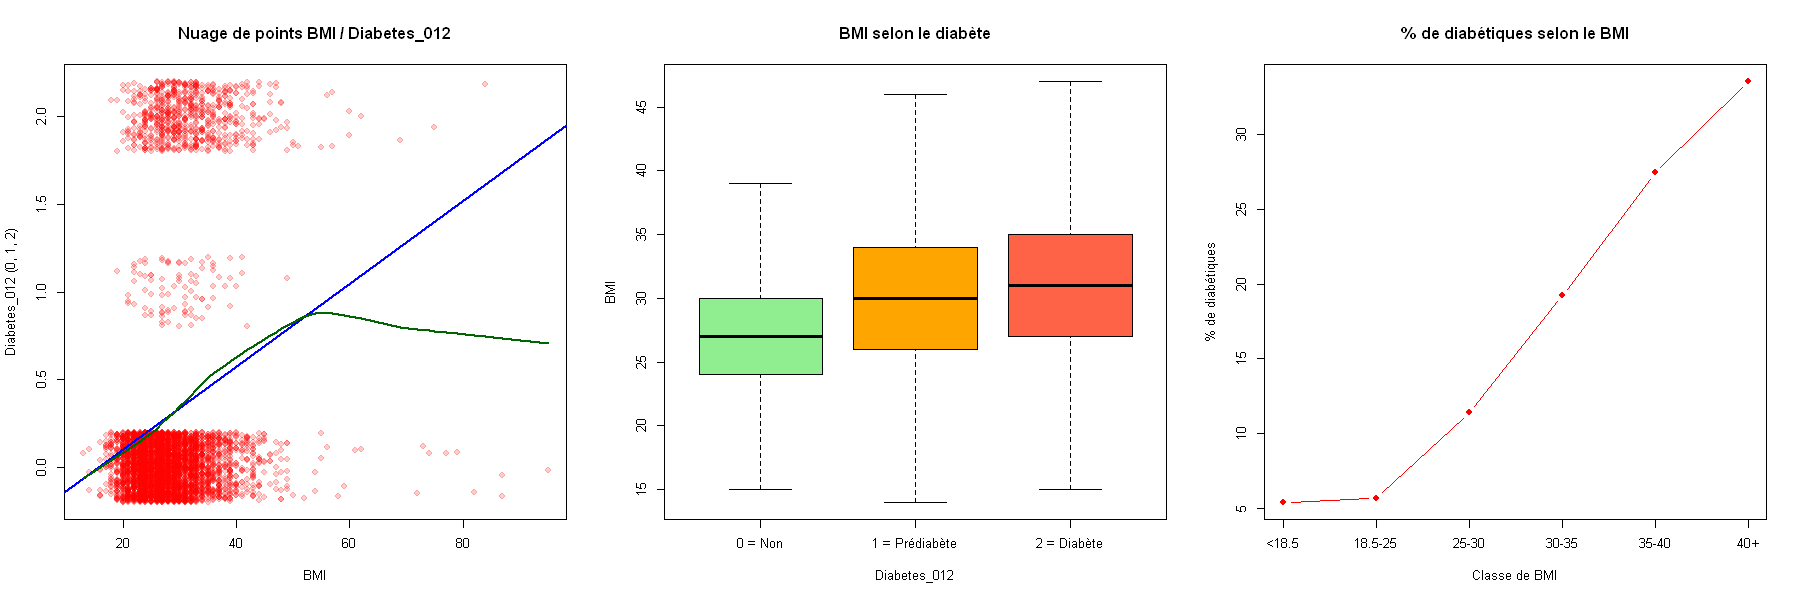

In [9]:
par(mfrow = c(1, 3))

# 1. Nuage de points (Y n'a que 3 valeurs, on ajoute du jitter)
plot(ech$BMI, jitter(ech$Diabetes_012), main = "Nuage de points BMI / Diabetes_012",
     col = rgb(1, 0, 0, 0.2), pch = 19, xlab = "BMI", ylab = "Diabetes_012 (0, 1, 2)")
abline(lm(Diabetes_012 ~ BMI, data = ech), col = "blue", lwd = 2)
lines(lowess(ech$BMI, ech$Diabetes_012, iter = 0), col = "darkgreen", lwd = 2)  # iter = 0 : suit la moyenne

# 2. Boxplot du BMI dans chaque groupe
boxplot(BMI ~ Diabetes_012, data = df, col = c("lightgreen", "orange", "tomato"),
        names = c("0 = Non", "1 = Prédiabète", "2 = Diabète"), main = "BMI selon le diabète",
        ylab = "BMI", outline = FALSE)

# 3. % de diabétiques selon les classes de BMI (OMS)
classes <- cut(x, breaks = c(0, 18.5, 25, 30, 35, 40, 100), right = FALSE,
               labels = c("<18.5", "18.5-25", "25-30", "30-35", "35-40", "40+"))
pct_diab <- tapply(y == 2, classes, mean) * 100
plot(1:6, pct_diab, type = "b", pch = 19, col = "red", xaxt = "n", main = "% de diabétiques selon le BMI",
     xlab = "Classe de BMI", ylab = "% de diabétiques")
axis(1, at = 1:6, labels = names(pct_diab))

par(mfrow = c(1, 1))

In [10]:
cat("BMI moyen par groupe :\n")
print(round(tapply(x, y, mean), 2))
cat("\n% de diabétiques par classe de BMI :\n")
print(round(pct_diab, 1))

BMI moyen par groupe :


    0     1     2 
27.74 30.72 31.94 



% de diabétiques par classe de BMI :


  <18.5 18.5-25   25-30   30-35   35-40     40+ 
    5.4     5.7    11.4    19.2    27.4    33.5 


**Interprétation :**
- **Nuage de points :** Y n'a que 3 valeurs (0, 1, 2), donc les points forment 3 bandes. La droite bleue et la courbe verte **montent** : plus le BMI est élevé, plus Y est grand. Au-delà de 55, la courbe verte redescend un peu, mais il y a très peu de personnes à ce niveau.
- **Boxplot :** le BMI moyen est de **27,7** chez les non-diabétiques, **30,7** chez les prédiabétiques et **31,9** chez les diabétiques. Les diabétiques sont en moyenne en **obésité** (BMI ≥ 30).
- **% de diabétiques :**
  - BMI normal (18,5-25) : **5,7 %** de diabétiques ;
  - obésité sévère (40+) : **33,5 %** de diabétiques, soit **6 fois plus**.
- **Type de relation :** **positive**. La hausse est forte entre 25 et 40, puis elle ralentit. C'est une relation **un peu non linéaire** (une courbe qui s'aplatit), ce qui justifie d'essayer une transformation.

### B.3 Linéariser la relation : transformation et restriction
1. **Données originales.**
2. **Transformation :** log(BMI). La courbe qui s'aplatit ressemble à un logarithme, donc on compose par log, comme le dit la remarque du cours.
3. **Restriction :** on retire les BMI aberrants (en dehors de [Q1 − 1,5 IQR ; Q3 + 1,5 IQR]).

In [11]:
# 1. Données originales
r_orig <- cor(x, y)
r2_orig <- summary(lm(y ~ x))$adj.r.squared

# 2. Transformation logarithmique de X
x_log <- log(x)
r_log <- cor(x_log, y)
r2_log <- summary(lm(y ~ x_log))$adj.r.squared

# 3. Restriction : on garde les BMI entre les bornes de l'IQR
q1 <- quantile(x, 0.25)
q3 <- quantile(x, 0.75)
borne_bas <- q1 - 1.5 * (q3 - q1)
borne_haut <- q3 + 1.5 * (q3 - q1)
filtre <- x >= borne_bas & x <= borne_haut
r_res <- cor(x[filtre], y[filtre])
r2_res <- summary(lm(y[filtre] ~ x[filtre]))$adj.r.squared

cat("Bornes de restriction :", borne_bas, "à", borne_haut, "| personnes gardées :", sum(filtre), "\n\n")
cat("Originales     : r =", round(r_orig, 3), "| R² ajusté =", round(r2_orig, 4), "\n")
cat("Transformation : r =", round(r_log, 3), "| R² ajusté =", round(r2_log, 4), "\n")
cat("Restriction    : r =", round(r_res, 3), "| R² ajusté =", round(r2_res, 4), "\n")

Bornes de restriction : 13.5 à 41.5 | personnes gardées : 243833 



Originales     : r = 0.224 | R² ajusté = 0.0503 


Transformation : r = 0.234 | R² ajusté = 0.0547 


Restriction    : r = 0.221 | R² ajusté = 0.0489 


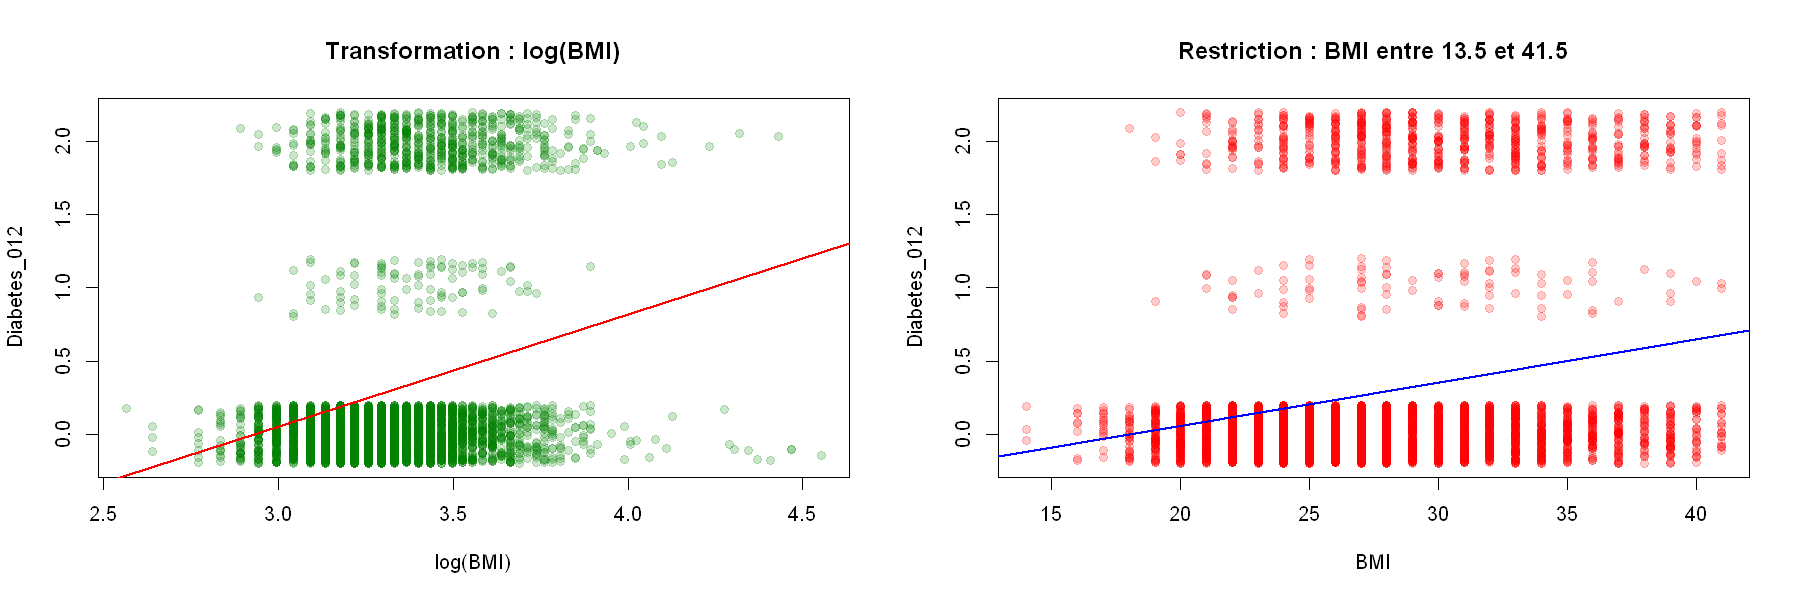

In [12]:
par(mfrow = c(1, 2))

plot(log(ech$BMI), jitter(ech$Diabetes_012), main = "Transformation : log(BMI)",
     col = rgb(0, 0.5, 0, 0.2), pch = 19, xlab = "log(BMI)", ylab = "Diabetes_012")
abline(lm(Diabetes_012 ~ log(BMI), data = ech), col = "red", lwd = 2)

ech_res <- ech[ech$BMI >= borne_bas & ech$BMI <= borne_haut, ]
plot(ech_res$BMI, jitter(ech_res$Diabetes_012), main = "Restriction : BMI entre 13.5 et 41.5",
     col = rgb(1, 0, 0, 0.2), pch = 19, xlab = "BMI", ylab = "Diabetes_012")
abline(lm(Diabetes_012 ~ BMI, data = ech_res), col = "blue", lwd = 2)

par(mfrow = c(1, 1))

**Interprétation :**
| Version | r | R² ajusté |
|---|---|---|
| Données originales | 0,224 | 0,0503 |
| **Transformation log(BMI)** | **0,234** | **0,0547** |
| Restriction (13,5 à 41,5) | 0,221 | 0,0489 |

- **La transformation log améliore un peu** la relation : r passe de 0,224 à **0,234**, et le R² ajusté de 0,050 à **0,055**. Le log « redresse » la courbe qui s'aplatissait.
- **La restriction diminue la relation** : en retirant les BMI supérieurs à 41,5 (3,9 % des personnes), on retire les personnes très obèses, qui sont justement les plus souvent diabétiques. On **perd de l'information utile**.
- **Choix :** la **transformation log(BMI)** est la meilleure solution.

### B.4 Force de la liaison : coefficient de Pearson et test d'hypothèse
**H0 : ρ = 0** contre **H1 : ρ ≠ 0**.

In [13]:
test_B <- cor.test(log(x), y)

cat("Coefficient de corrélation r (log(BMI), Diabetes_012) :", test_B$estimate, "\n")
cat("p-value du test :", test_B$p.value, "\n")
cat("Spearman (vérification) :", cor(x, y, method = "spearman"), "\n")

Coefficient de corrélation r (log(BMI), Diabetes_012) : 0.2338598 


p-value du test : 0 


Spearman (vérification) : 0.2358866 


**Interprétation :**
- **r = 0,23** : liaison linéaire **positive** et **faible**. Plus le BMI est élevé, plus le risque de diabète augmente.
- **p-value < 0,05** (pratiquement 0) : on **rejette H0**. La liaison est **significative**, elle n'est pas due au hasard.
- **Spearman = 0,24** confirme le même résultat.
- **Pourquoi r reste faible ?** La cible n'a que 3 valeurs, et beaucoup de personnes en surpoids ne sont pas diabétiques. Le BMI seul ne suffit pas à prédire le diabète, mais il y contribue clairement (6 fois plus de diabétiques chez les obèses sévères).

### B.5 Décision (cas 1 : variable explicative et variable cible)
- **Règle du cours :** si |r| est élevé et que la p-value est inférieure à 0,05, la variable est **utile** pour prédire la cible.
- **Ici :** p-value < 0,05 et r = 0,23. C'est l'**une des corrélations les plus fortes** avec le diabète dans notre groupe de variables (voir la partie C).

✅ **Décision : on conserve BMI dans le modèle, de préférence sous la forme log(BMI).**

---
## 🔹 Partie C : Bivariée sans variable cible, toutes les paires du groupe
Comme dans la partie 2.5 du cours, on étudie **toutes les paires** des variables choisies par le groupe avec une **matrice de corrélation** et une **matrice de nuages de points** (`pairs()`).

In [14]:
variables <- c("PhysHlth", "GenHlth", "Income", "Education", "Age", "MentHlth", "BMI", "Diabetes_012")

matrice <- cor(df[, variables])
round(matrice, 2)

,PhysHlth,GenHlth,Income,Education,Age,MentHlth,BMI,Diabetes_012
PhysHlth,1.00,0.52,-0.27,-0.16,0.10,0.35,0.12,0.18
GenHlth,0.52,1.00,-0.37,-0.28,0.15,0.30,0.24,0.30
Income,-0.27,-0.37,1.00,0.45,-0.13,-0.21,-0.10,-0.17
Education,-0.16,-0.28,0.45,1.00,-0.10,-0.10,-0.10,-0.13
Age,0.10,0.15,-0.13,-0.10,1.00,-0.09,-0.04,0.19
MentHlth,0.35,0.30,-0.21,-0.10,-0.09,1.00,0.09,0.07
BMI,0.12,0.24,-0.10,-0.10,-0.04,0.09,1.00,0.22
Diabetes_012,0.18,0.30,-0.17,-0.13,0.19,0.07,0.22,1.00


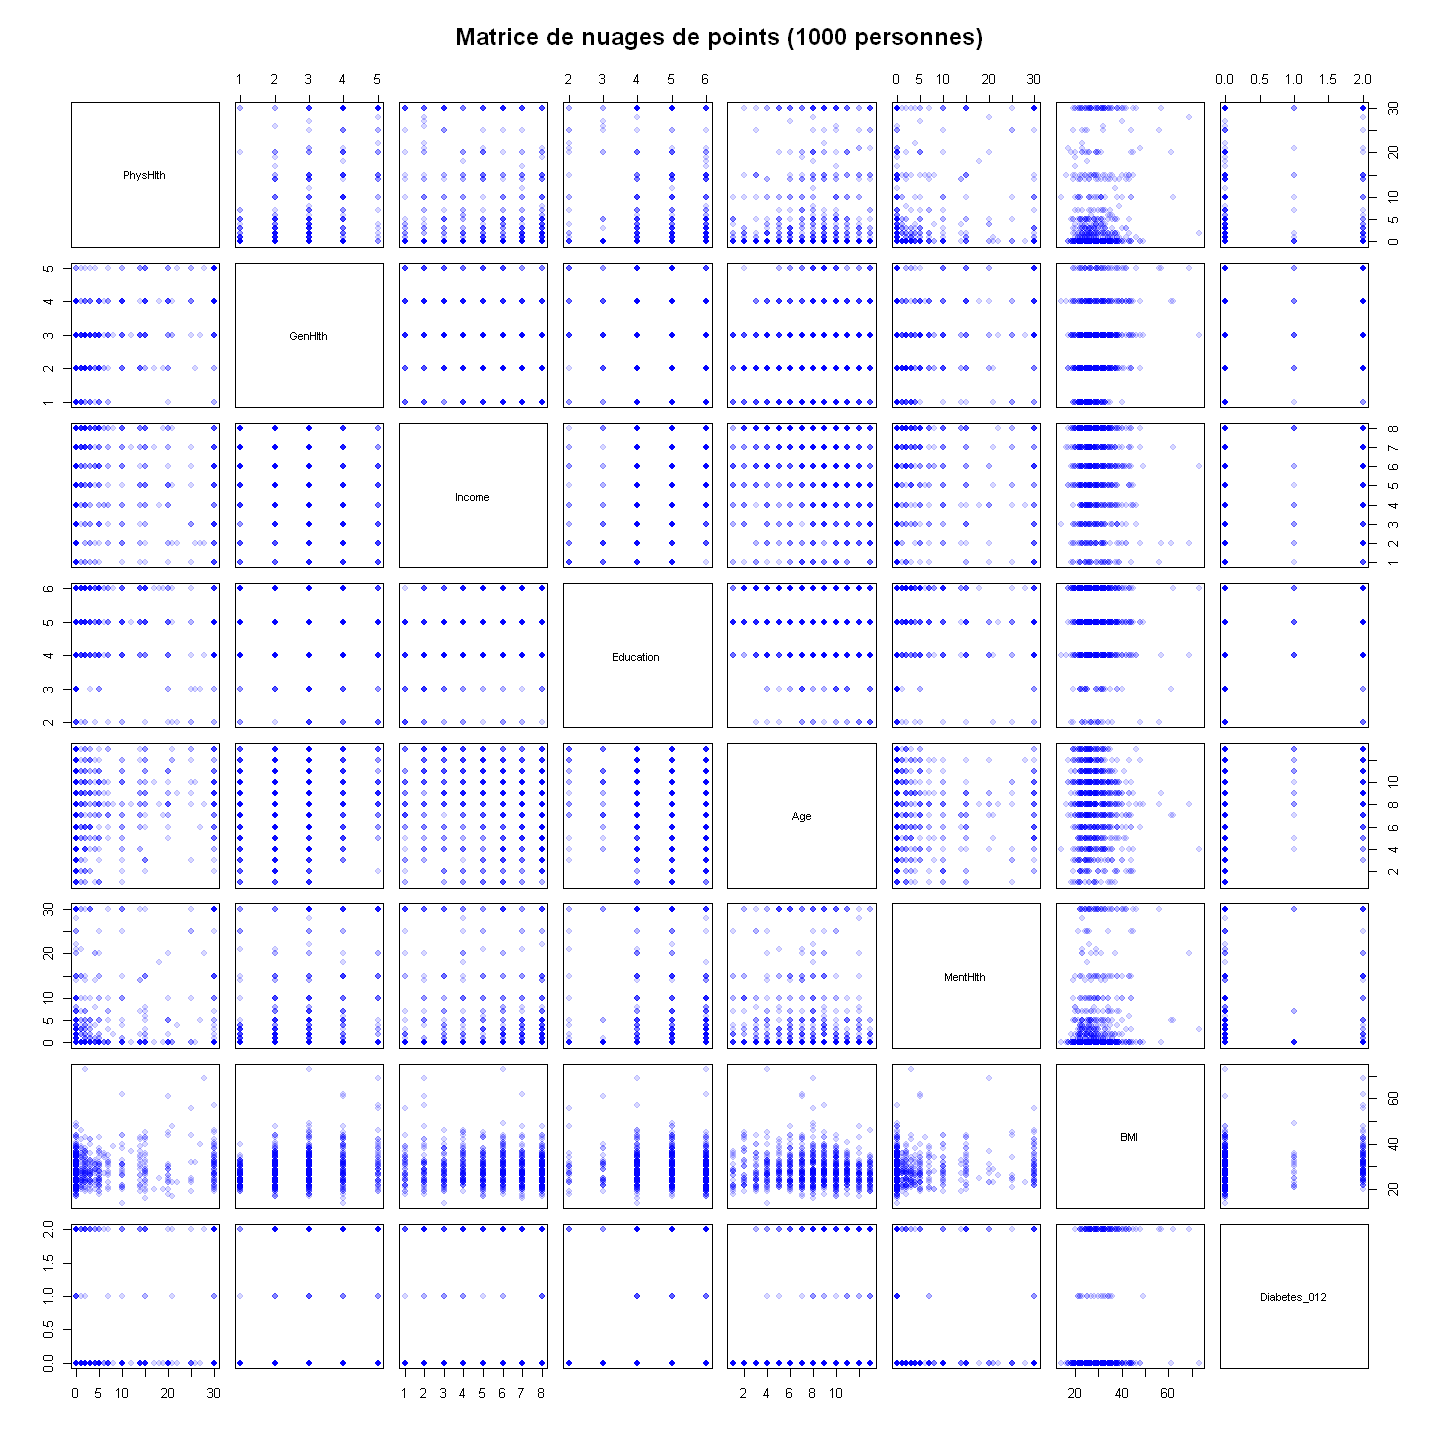

In [15]:
options(repr.plot.width = 12, repr.plot.height = 12)
pairs(ech[1:1000, variables], pch = 19, col = rgb(0, 0, 1, 0.15), main = "Matrice de nuages de points (1000 personnes)")
options(repr.plot.width = 15, repr.plot.height = 5)

**Interprétation :**
- **Multicolinéarité :** **aucune paire** de variables explicatives ne dépasse |r| = 0,70. La plus forte est **GenHlth et PhysHlth (0,52)**, puis Income et Education (0,45). On peut **garder toutes les variables**.
- **Lien avec la cible (Diabetes_012) :**
  - **GenHlth : 0,30** (la plus forte) ;
  - **BMI : 0,22** ;
  - Age : 0,19 ;
  - PhysHlth : 0,18 ;
  - Income : -0,17 ;
  - Education : -0,13 ;
  - MentHlth : 0,07 (la plus faible).
- Les nuages de points montrent surtout des **colonnes et des lignes**, parce que la plupart de ces variables n'ont que quelques valeurs (des codes). Seul BMI ressemble à une vraie variable continue.

---
## ✅ Conclusion
| | Couple A : Income et PhysHlth | Couple B : BMI et Diabetes_012 |
|---|---|---|
| Cas du cours | Cas 2 : deux explicatives | Cas 1 : explicative et cible |
| Type de relation | Négative, presque linéaire | Positive, un peu non linéaire |
| Meilleure version | Données originales | Transformation log(BMI) |
| Pearson r | -0,27 | 0,23 |
| p-value | < 0,05 : H0 rejetée | < 0,05 : H0 rejetée |
| Décision | Pas de multicolinéarité : on garde les deux | Variable utile : on garde BMI (en log) |

- **Couple A :** plus le revenu est faible, plus les personnes sont malades. Le lien est faible mais significatif. Les deux variables restent dans le modèle.
- **Couple B :** plus le BMI est élevé, plus il y a de diabétiques, jusqu'à 6 fois plus chez les obèses sévères. BMI est une variable **utile** pour prédire le diabète.